# Part 4: Gradient Descent in Code

In [19]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.optimize as opt
from scipy.optimize import minimize, approx_fprime

##### 1. Setup Data from handwritten **maths**

In [20]:
X = np.array([
    [1.0, 3.0],
    [4.0, 10.0]
])
y = np.array([
    [5.0],
    [6.0]
])

2.Setting initial parameters

In [21]:
m = np.array([
    [-1.0],
    [2.0]
])
b = np.array([
    [1.0],
    [1.0]
])

alpha = 0.01
num_iterations = 3
n = len(y)

3. Calculate the starting predictions and cost

In [22]:
y_hat_initial = X @ m + b
error_initial = y_hat_initial - y
initial_cost = (1.0 / n) * np.sum(error_initial ** 2)

print("Initial predictions y_hat =\n", y_hat_initial)
print("Initial errors =\n", error_initial)
print(f"Initial cost J = {initial_cost:.4f}")

Initial predictions y_hat =
 [[ 6.]
 [17.]]
Initial errors =
 [[ 1.]
 [11.]]
Initial cost J = 61.0000


4. history tracking

In [23]:
m_history = [m.copy()]
b_history = [b.copy()]
cost_history = [(1.0 / n) * np.sum(error_initial**2)]

5. Step-by-step Gradient Descent Loop

In [24]:
for i in range(1, num_iterations + 1):
    # Step 1: predictions from the current parameters
    y_hat = X @ m + b

    # Step 2: prediction errors
    error = y_hat - y

    # Step 3: gradients of the MSE cost
    dj_dm = (2.0 / n) * (X.T @ error)
    dj_db = (2.0 / n) * error  # vector bias, matching b's shape

    # Step 4: update each parameter exactly once
    m = m - alpha * dj_dm
    b = b - alpha * dj_db

    # Step 5: calculate cost using the updated parameters
    updated_y_hat = X @ m + b
    updated_error = updated_y_hat - y
    updated_cost = (1.0 / n) * np.sum(updated_error ** 2)

    # Step 6: save the updated state for plotting
    m_history.append(m.copy())
    b_history.append(b.copy())
    cost_history.append(updated_cost)
    print(f"\n{'=' * 12} ITERATION {i} {'=' * 12}")
    print("Predictions before update:\n", y_hat)
    print("Errors before update:\n", error)
    print("Gradient with respect to m:\n", dj_dm)
    print("Gradient with respect to b:\n", dj_db)
    print("Updated m:\n", m)
    print("Updated b:\n", b)
    print("Predictions after update:\n", updated_y_hat)
    print(f"Cost after update = {updated_cost:.6f}")


============ ITERATION 1 ============
Predictions before update:
 [[ 6.]
 [17.]]
Errors before update:
 [[ 1.]
 [11.]]
Gradient with respect to m:
 [[ 45.]
 [113.]]
Gradient with respect to b:
 [[ 1.]
 [11.]]
Updated m:
 [[-1.45]
 [ 0.87]]
Updated b:
 [[0.99]
 [0.89]]
Predictions after update:
 [[2.15]
 [3.79]]
Cost after update = 6.503300

============ ITERATION 2 ============
Predictions before update:
 [[2.15]
 [3.79]]
Errors before update:
 [[-2.85]
 [-2.21]]
Gradient with respect to m:
 [[-11.69]
 [-30.65]]
Gradient with respect to b:
 [[-2.85]
 [-2.21]]
Updated m:
 [[-1.3331]
 [ 1.1765]]
Updated b:
 [[1.0185]
 [0.9121]]
Predictions after update:
 [[3.2149]
 [7.3447]]
Cost after update = 2.497400

============ ITERATION 3 ============
Predictions before update:
 [[3.2149]
 [7.3447]]
Errors before update:
 [[-1.7851]
 [ 1.3447]]
Gradient with respect to m:
 [[3.5937]
 [8.0917]]
Gradient with respect to b:
 [[-1.7851]
 [ 1.3447]]
Updated m:
 [[-1.369037]
 [ 1.095583]]
Updated b:
 [

In [25]:
print("\nFinal predictions:\n", X @ m + b)
print("Final m:\n", m)
print("Final b:\n", b)
print(f"Final cost = {cost_history[-1]:.6f}")

assert len(m_history) == num_iterations + 1
assert len(b_history) == num_iterations + 1
assert len(cost_history) == num_iterations + 1
print("\nCheck passed: exactly three updates were recorded.")


Final predictions:
 [[2.954063]
 [6.378335]]
Final m:
 [[-1.369037]
 [ 1.095583]]
Final b:
 [[1.036351]
 [0.898653]]
Final cost = 2.164498

Check passed: exactly three updates were recorded.


6. Scipy Minimization Verification

In [26]:
def cost_from_flat_params(params):
    """Return the MSE cost for flattened [m1, m2, b1, b2] parameters."""
    m_values = params[:2].reshape(2, 1)
    b_values = params[2:4].reshape(2, 1)
    predictions = X @ m_values + b_values
    return (1.0 / n) * np.sum((predictions - y) ** 2)


def compute_scipy_gradient(function, params, epsilon=1e-6):
    """Estimate a scalar function's gradient with SciPy finite differences."""
    return approx_fprime(params, function, epsilon)

final_params = np.concatenate([m.ravel(), b.ravel()])
scipy_gradient = compute_scipy_gradient(cost_from_flat_params, final_params)

 #### Analytical gradient evaluated at exactly the same final parameters.

In [27]:
final_error = (X @ m + b) - y
analytic_dm = (2.0 / n) * (X.T @ final_error)
analytic_db = (2.0 / n) * final_error
analytic_gradient = np.concatenate([analytic_dm.ravel(), analytic_db.ravel()])

parameter_names = ["m1", "m2", "b1", "b2"]
print("Gradient comparison at final parameters:")
for name, analytic, numerical in zip(parameter_names, analytic_gradient, scipy_gradient):
    print(f"{name}: analytical = {analytic: .8f} | SciPy numerical = {numerical: .8f}")

max_difference = np.max(np.abs(analytic_gradient - scipy_gradient))
print(f"\nMaximum absolute difference = {max_difference:.2e}")
assert np.allclose(analytic_gradient, scipy_gradient, atol=1e-4, rtol=1e-4)
print("Check passed: SciPy's numerical gradients agree with the analytical gradients.")

Gradient comparison at final parameters:
m1: analytical = -0.53259700 | SciPy numerical = -0.53258850
m2: analytical = -2.35446100 | SciPy numerical = -2.35440650
b1: analytical = -2.04593700 | SciPy numerical = -2.04593650
b2: analytical =  0.37833500 | SciPy numerical =  0.37833550

Maximum absolute difference = 5.45e-05
Check passed: SciPy's numerical gradients agree with the analytical gradients.


##### 4. Matplotlib Visualization

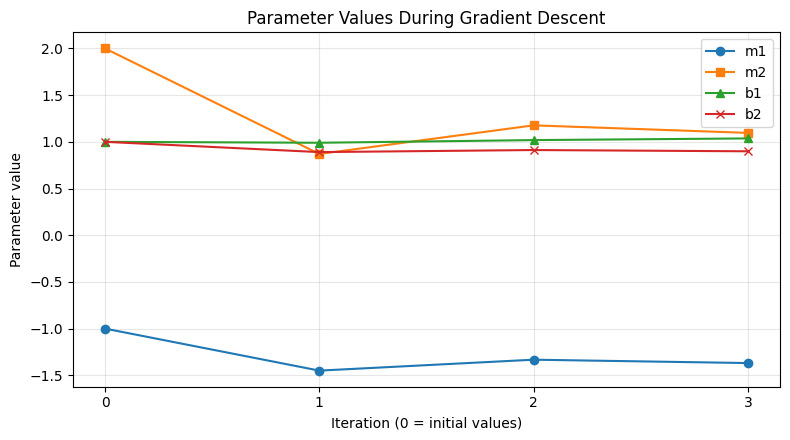

In [28]:
m_hist = np.vstack([item.reshape(1, 2) for item in m_history])
b_hist = np.vstack([item.reshape(1, 2) for item in b_history])
steps = np.arange(num_iterations + 1)

# Plot 1: how the parameters change from iteration 0 through iteration 3
plt.figure(figsize=(8, 4.5))
plt.plot(steps, m_hist[:, 0], marker="o", label="m1")
plt.plot(steps, m_hist[:, 1], marker="s", label="m2")
plt.plot(steps, b_hist[:, 0], marker="^", label="b1")
plt.plot(steps, b_hist[:, 1], marker="x", label="b2")
plt.title("Parameter Values During Gradient Descent")
plt.xlabel("Iteration (0 = initial values)")
plt.ylabel("Parameter value")
plt.xticks(steps)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

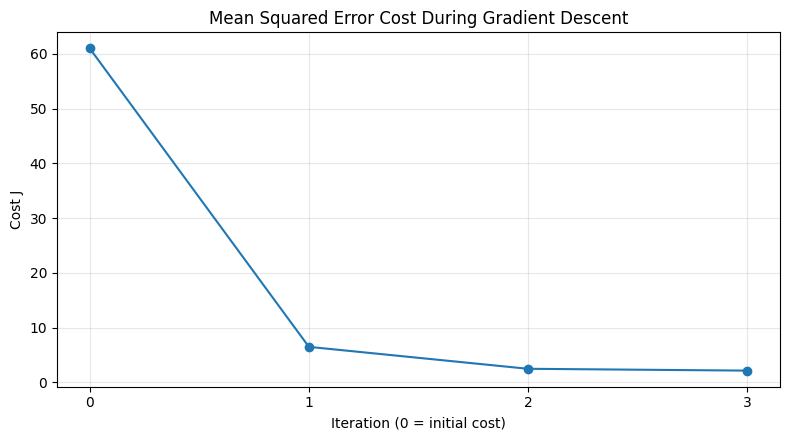

Cost history: [np.float64(61.0), np.float64(6.5033), np.float64(2.4974), np.float64(2.164498)]


In [29]:
# Plot 2: cost at the initial state and after each update
plt.figure(figsize=(8, 4.5))
plt.plot(steps, cost_history, marker="o")
plt.title("Mean Squared Error Cost During Gradient Descent")
plt.xlabel("Iteration (0 = initial cost)")
plt.ylabel("Cost J")
plt.xticks(steps)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Cost history:", [round(value, 6) for value in cost_history])